# Notebook 6.3 — Patch sizing from spatial autocorrelation (FFT)

**Goal.** Choose the patch size *from the data* instead of guessing it. A patch should be about the size over
which neighbouring voxels are actually related; measure that scale — the **correlation length** — and let it
set the patch. This is a **sizing study only**: stride/overlap and any new noise mechanism are out of scope.

**Why this matters for the wider project.** The patch size fixes `p` (voxels per patch), and `p` fixes how
hard the noise construction is — notebook 6.1 showed privacy needs the *full* rank of the patch, so a bigger
patch is a strictly harder noise problem. So "what size?" is not cosmetic; it sets the difficulty of
everything downstream.

**How to read this notebook.** It is meant to be followed start to finish without outside help. The first two
sections explain the idea and the tool; then six experiments (A–F) each ask one question, show one figure, and
end with a one-line read-off:

- **A** — does the tool even work? (validate it on fields whose length we know)
- **B** — one cubic size, or one per axis?
- **C** — size on the output image, or on the field we actually protect?
- **D** — is one size defensible across the whole brain?
- **E** — real OASIS numbers.
- **F** — size → `p` → the noise dimensionality (the hand-off back to 6.1).

Frozen modules are untouched; every estimator helper lives in this notebook.

*Prerequisites: notebooks 4–5; notebook 6.1 for the dimensionality hand-off in Part F.*

## Background — what we are measuring, and with what

### What is a correlation length?

Take any voxel and its neighbour one step away: their values are usually similar. Two steps away, a bit less
similar. Far enough apart, unrelated. The **correlation length** is a single number for *how far apart two
voxels have to be before they stop being related* — the spatial scale of smoothness.

We read it off the **autocorrelation curve**: for each spatial offset ("lag") we measure how correlated a
voxel is with the voxel that far away, averaged over the whole (masked) volume. That curve starts at 1 at zero
lag (a voxel equals itself) and decays toward 0. A **short** correlation length ⇒ the curve drops fast ⇒ a
rough field. A **long** length ⇒ the curve decays slowly ⇒ a smooth field. Brain gray-matter maps are smooth,
so their length is several voxels — which is exactly why the noise covariance turned out low-rank in 6.1.

### The estimator (the measuring tool)

"The estimator" just means the pipeline that turns *a field* into *a length*. It is three small functions:

1. `masked_acf(x, mask)` — compute the autocorrelation of the field via the FFT (`IFFT(|FFT(x)|²)`, the
   Wiener–Khinchin identity — one FFT per volume, very cheap), **corrected for the brain mask** so the
   zero background and the brain's edge don't bias the result.
2. `axis_profiles(acf)` — read that autocorrelation along each axis, giving one decay curve per axis.
3. `corr_lengths(profile)` — collapse one curve into a single length number.

### Why three length definitions?

"The correlation length" is a *summary of a whole curve*, and there is more than one sensible way to summarize
where a curve decays — so we compute three and pick the convention later:

- **1/e length** — the lag where the curve crosses 0.37 (≈ 1/e). One point on the curve.
- **0.5 length** — the lag where it crosses 0.5. A stricter point (smaller number).
- **integral length** — the area under the whole curve. Uses all of it (robust to noise), with its own
  scaling constant.

They agree on the *shape* of the answer (smoother ⇒ longer, by all three) and differ only in absolute value.
The patch-size mapping `side ≈ c · length` has a free constant `c`, which absorbs that offset — so the choice
matters less for the final size than it looks.

### One thing to keep straight: two different roles for "length"

- In **Part A only** we *set* the length ourselves, to build test fields with a known answer so we can grade
  the estimator. That length is an input we choose.
- **Everywhere else** the length is the *unknown we are measuring* from a field handed to us. We don't know it
  until the estimator tells us.

So "we determine the length ourselves" is true only in A, and only because A is the test rig.

In [1]:
import sys, os, numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter
from matplotlib.colors import to_rgba
for cand in [".", "harness", os.path.expanduser("~/harness")]:
    if os.path.exists(os.path.join(cand, "privacy_harness.py")):
        sys.path.insert(0, cand); break
import privacy_harness as ph
plt.rcParams.update({"figure.dpi":110, "axes.grid":True, "grid.alpha":.3})

# ---------- the estimator: field -> correlation length ----------
def masked_acf(x, mask):
    # Spatial autocorrelation of x inside mask, via FFT, corrected for the mask boundary.
    # FFT assumes the field wraps around periodically, so the zero background and brain edge would
    # bias every length. We zero-pad (no wraparound) and divide by the mask's own autocorrelation
    # (the count of valid voxel pairs at each lag). Returns acf normalized so acf[lag 0] = 1.
    x = np.asarray(x, float); m = np.asarray(mask, float)
    mu = x[m > 0].mean(); xd = (x - mu) * m
    pad = [(0, s) for s in x.shape]
    X = np.fft.fftn(np.pad(xd, pad)); M = np.fft.fftn(np.pad(m, pad))
    num = np.fft.ifftn(np.abs(X)**2).real; den = np.fft.ifftn(np.abs(M)**2).real
    acf = np.where(den > 1e-6, num / np.maximum(den, 1e-9), 0.0)
    return acf / acf.flat[0]

def axis_profiles(acf, max_lag):
    # The 1-D autocorrelation curve along each axis (lag 0..max_lag).
    profs = []
    for ax in range(acf.ndim):
        sl = [slice(0, 1)] * acf.ndim; sl[ax] = slice(0, max_lag)
        profs.append(acf[tuple(sl)].ravel())
    return profs

def corr_lengths(prof):
    # Collapse one autocorrelation curve into three lengths: (1/e crossing, 0.5 crossing, integral).
    def cross(th):                                  # first lag where the curve drops below th (interpolated)
        b = np.where(prof < th)[0]
        if len(b) == 0: return float(len(prof))
        i = b[0]
        return 0.0 if i == 0 else (i-1) + (prof[i-1]-th)/(prof[i-1]-prof[i]+1e-12)
    zc = np.where(prof <= 0)[0]
    integ = prof[:zc[0]].sum() if len(zc) else prof.sum()   # area under the positive part
    return cross(1/np.e), cross(0.5), float(integ)

def lengths_per_axis(x, mask, max_lag=30):
    return [corr_lengths(p) for p in axis_profiles(masked_acf(x, mask), max_lag)]

# ---------- synthetic test fields with a KNOWN length (used only to validate the tool) ----------
def grf(shape, L, seed=0):
    # Gaussian random field with an EXACT Gaussian autocorrelation exp(-r^2 / 2L^2).
    # Because we build it, we know its length analytically: 1/e = L*sqrt2, 0.5 = 1.177*L, integral = 1.253*L.
    rng = np.random.default_rng(seed)
    ks = np.meshgrid(*[np.fft.fftfreq(s)*2*np.pi for s in shape], indexing="ij")
    amp = np.exp(-(L**2)*sum(k**2 for k in ks)/4.0)
    return np.fft.ifftn(np.fft.fftn(rng.standard_normal(shape))*amp).real
print("estimator ready")

estimator ready


In [2]:
# ---- extra helpers for the revised F: GM mask (as in 7.1), voxel size, and robust sizing fields ----
from scipy import ndimage as _ndi
def gm_threshold_mask(volumes, how="otsu"):
    """Real GM mask by thresholding the mean GM map (Otsu) + fill holes + largest component -- the same
    construction 7.1 uses, so sizing is measured on the same voxels the tiling uses (not the ~96% whole-head
    mask, which includes near-constant background and inflates correlation lengths)."""
    gm_mean = np.asarray(volumes, float).mean(0)
    finite = np.isfinite(gm_mean) & (gm_mean > 0)
    if how == "otsu":
        try:
            from skimage.filters import threshold_otsu
            thr = float(threshold_otsu(gm_mean[finite])) if finite.any() else 0.0
        except Exception:
            thr = float(np.percentile(gm_mean[finite], 60)) if finite.any() else 0.0
    else:
        thr = float(how)
    m = _ndi.binary_fill_holes(gm_mean > thr)
    lab, n = _ndi.label(m)
    if n > 1:
        sizes = _ndi.sum(np.ones_like(lab), lab, range(1, n + 1))
        m = lab == (1 + int(np.argmax(sizes)))
    return (m & np.isfinite(gm_mean)), thr

def oasis_voxel_size_mm():
    """Voxel size (mm) of the OASIS GM maps, read from the image header; None if unavailable."""
    try:
        from nilearn.datasets import fetch_oasis_vbm
        import nibabel as nib
        img = nib.load(fetch_oasis_vbm(n_subjects=1).gray_matter_maps[0])
        return tuple(round(float(z), 3) for z in img.header.get_zooms()[:3])
    except Exception as e:
        print("  (voxel size unavailable:", e, ")")
        return None

def sizing_fields(vols, pipeline=None):
    """Candidate per-voxel sizing fields for the MEAN release: the output image, and three summaries of the
    LOO perturbations d_i -- the outlier-driven max, and two outlier-resistant spreads (std, 90%-trimmed RMS)."""
    pipeline = pipeline or ph.pipeline_mean
    _, D, _ = ph.loo_artifacts(vols, pipeline)
    vshape = np.asarray(vols).shape[1:]
    D = np.asarray(D).reshape(np.asarray(D).shape[0], *vshape)
    absD = np.abs(D); Nn = D.shape[0]; k = max(1, int(round(0.9 * Nn)))
    trimmed = np.sqrt(np.mean(np.sort(absD, 0)[:k] ** 2, 0))
    return {"mean image": np.asarray(vols).mean(0),
            "max_i|d_i|  (old)": absD.max(0),
            "std_i(d_i)  (robust)": D.std(0),
            "90%-trim RMS|d| (robust)": trimmed}
print("revised-F helpers ready (gm_threshold_mask, oasis_voxel_size_mm, sizing_fields)")

revised-F helpers ready (gm_threshold_mask, oasis_voxel_size_mm, sizing_fields)


## Anatomy of one measurement

Before any experiment, here is the whole idea in one picture. We take a single smooth field, compute its
autocorrelation curve, and mark the three lengths on it — so "correlation length" and "three definitions" stop
being words. The curve falls from 1; the **1/e** and **0.5** lengths are where it crosses those heights; the
**integral** length is the shaded area under it.

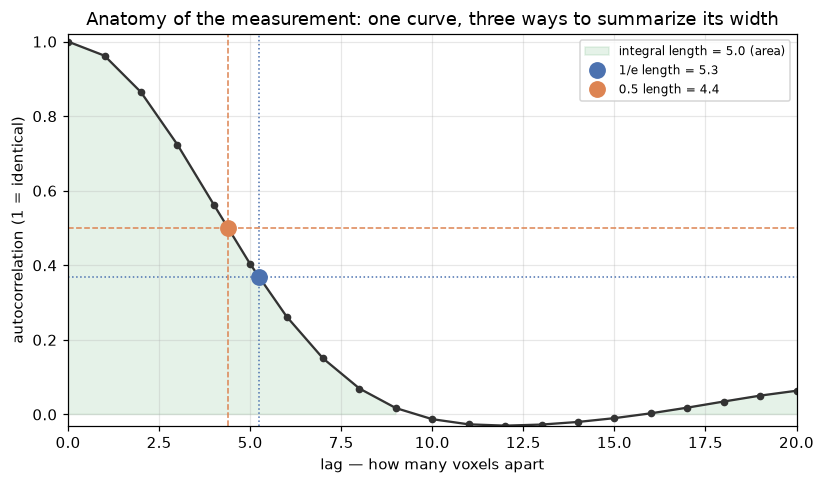

In [3]:
x = grf((64, 64, 64), L=4.0, seed=1)
prof = axis_profiles(masked_acf(x, np.ones((64, 64, 64), bool)), 25)[0]
le, lh, li = corr_lengths(prof); lags = np.arange(len(prof))

fig, ax = plt.subplots(figsize=(7.6, 4.5))
ax.fill_between(lags, 0, prof, where=prof > 0, color="#55a868", alpha=.15, label=f"integral length = {li:.1f} (area)")
ax.plot(lags, prof, "o-", color="#333", ms=4)
ax.axhline(1/np.e, color="#4c72b0", ls=":", lw=1); ax.axvline(le, color="#4c72b0", ls=":", lw=1)
ax.axhline(0.5, color="#dd8452", ls="--", lw=1); ax.axvline(lh, color="#dd8452", ls="--", lw=1)
ax.plot(le, 1/np.e, "o", color="#4c72b0", ms=10, label=f"1/e length = {le:.1f}")
ax.plot(lh, 0.5, "o", color="#dd8452", ms=10, label=f"0.5 length = {lh:.1f}")
ax.set_xlim(0, 20); ax.set_ylim(-0.03, 1.02)
ax.set_xlabel("lag — how many voxels apart"); ax.set_ylabel("autocorrelation (1 = identical)")
ax.set_title("Anatomy of the measurement: one curve, three ways to summarize its width")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

## A — Does the tool work? (validate on known ground truth)

On a real brain we have no ground truth, so a biased estimator would go unnoticed. A fixes that: we build
fields whose length we *set* (via `grf`), run the estimator, and check the output matches the value the
formula predicts (`1/e = L·√2`, `0.5 = 1.177·L`, `integral = 1.253·L`). If the tool is unbiased, every point
lands on the diagonal. Passing A checks three things at once: the length is **recovered** (no bias), the
**mask/boundary correction works** (or the points would drift off), and it reveals the tool's **limits**.

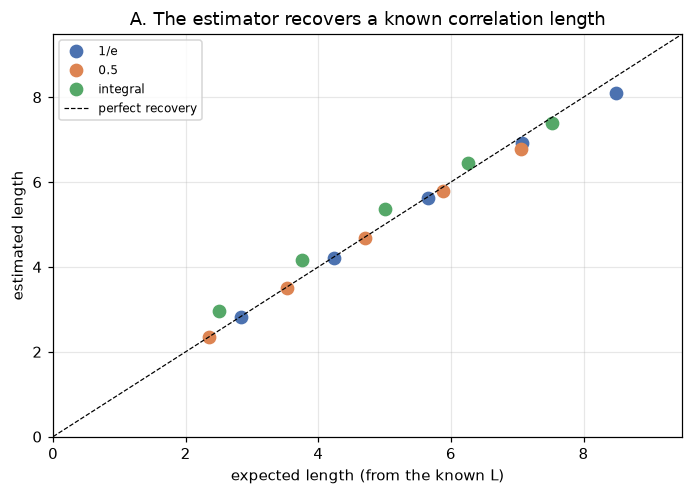

 true_L  est_1/e  exp_1/e  est_0.5  exp_0.5  est_int  exp_int
    2.0     2.81     2.83     2.34     2.35     2.96     2.51
    3.0     4.21     4.24     3.51     3.53     4.16     3.76
    4.0     5.62     5.66     4.68     4.71     5.35     5.01
    5.0     6.93     7.07     5.80     5.88     6.44     6.26
    6.0     8.09     8.49     6.78     7.06     7.38     7.52


In [4]:
Ls = [2.0, 3.0, 4.0, 5.0, 6.0]; m = np.ones((64, 64, 64), bool); rows = []
for L in Ls:
    le, lh, li = corr_lengths(axis_profiles(masked_acf(grf((64,64,64), L, seed=3), m), 30)[0])
    rows.append((L, le, L*np.sqrt(2), lh, 1.177*L, li, 1.253*L))
A = pd.DataFrame(rows, columns=["true_L","est_1/e","exp_1/e","est_0.5","exp_0.5","est_int","exp_int"])

fig, ax = plt.subplots(figsize=(6.4, 4.6))
for est, exp, lbl, c in [("est_1/e","exp_1/e","1/e","#4c72b0"),("est_0.5","exp_0.5","0.5","#dd8452"),
                         ("est_int","exp_int","integral","#55a868")]:
    ax.plot(A[exp], A[est], "o", color=c, ms=8, label=lbl)
lim = [0, A[["est_1/e","exp_1/e"]].values.max()+1]
ax.plot(lim, lim, "k--", lw=.8, label="perfect recovery"); ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel("expected length (from the known L)"); ax.set_ylabel("estimated length")
ax.set_title("A. The estimator recovers a known correlation length"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
print(A.round(2).to_string(index=False))

**Read-off (A).** The 1/e and 0.5 lengths land on the diagonal; the integral length tracks it on a parallel
line (its own constant). One honest limit, visible at the largest `L`: when the correlation length approaches
the region size, a finite box biases the estimate downward. So lengths are trustworthy when the length is
small relative to the masked region — the realistic regime for brain patches — and to be read with caution
when a field is smooth over a large fraction of the region.

## B — One cubic size, or one per axis?

Two separate choices hide here. **Measuring** a length per axis is always free — the FFT gives a curve per
axis, so we always get `(Lx, Ly, Lz)`. The real decision is whether to **size** per axis: a single cube is
simpler, but if the axes genuinely differ, a cube mis-sizes them. The deciding number is the **anisotropy
ratio** `max(L)/min(L)`: near 1 ⇒ a cube is fine; well above 1 ⇒ use an anisotropic `(kx,ky,kz)`.

Below, a field smoothed differently along each axis (σ = 2, 3.5, 6). **Left:** the three autocorrelation
curves — you can *see* the smoother axis decay slower. **Right:** the per-axis lengths against one cubic size
(the mean across axes) — the cube is wrong for the short *and* the long axis, symmetrically.

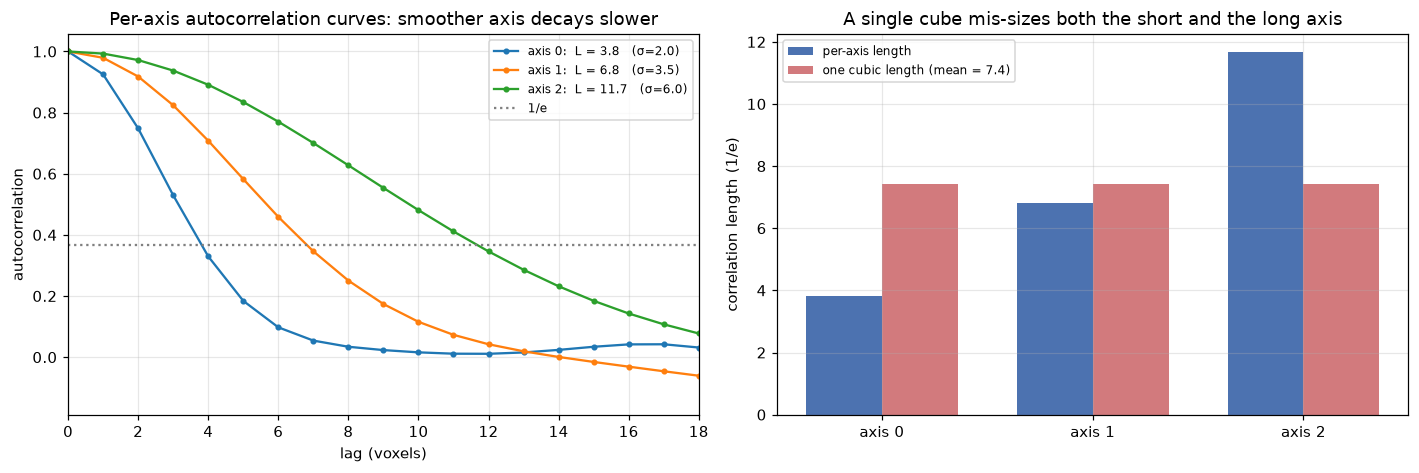

per-axis 1/e lengths: [np.float64(3.81), np.float64(6.81), np.float64(11.66)]  | anisotropy ratio = 3.06


In [5]:
true = [2.0, 3.5, 6.0]
x = gaussian_filter(np.random.default_rng(7).standard_normal((64, 64, 64)), sigma=true, mode="wrap")
profs = axis_profiles(masked_acf(x, np.ones((64,64,64), bool)), 25)
per = [corr_lengths(p)[0] for p in profs]          # 1/e length per axis
iso = float(np.mean(per))                          # one isotropic (cube) length = mean across axes

fig, ax = plt.subplots(1, 2, figsize=(13, 4.4))
for a, (p, L, t) in enumerate(zip(profs, per, true)):
    ax[0].plot(p, "o-", ms=3, label=f"axis {a}:  L = {L:.1f}   (σ={t})")
ax[0].axhline(1/np.e, color="grey", ls=":", label="1/e"); ax[0].set_xlim(0, 18)
ax[0].set_xlabel("lag (voxels)"); ax[0].set_ylabel("autocorrelation")
ax[0].set_title("Per-axis autocorrelation curves: smoother axis decays slower"); ax[0].legend(fontsize=8)

xs = np.arange(3); w = 0.36
ax[1].bar(xs-w/2, per, w, label="per-axis length", color="#4c72b0")
ax[1].bar(xs+w/2, [iso]*3, w, label=f"one cubic length (mean = {iso:.1f})", color=to_rgba("#c44e52", .75))
ax[1].set_xticks(xs); ax[1].set_xticklabels([f"axis {i}" for i in range(3)])
ax[1].set_ylabel("correlation length (1/e)")
ax[1].set_title("A single cube mis-sizes both the short and the long axis"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()
print("per-axis 1/e lengths:", [round(v,2) for v in per], " | anisotropy ratio =", round(max(per)/min(per), 2))

**Read-off (B).** The per-axis lengths separate in proportion to the true per-axis smoothness, and a single
cube (their mean) over-sizes the short axis and under-sizes the long one. So: **always measure per axis**;
**size per axis only when the anisotropy ratio is well above 1**. Two reasons it often will be on real data:
non-cubic voxels (a fixed voxel count is already anisotropic in millimetres — consider sizing in mm), and
genuine directional anatomy.

## C — Size on the output image, or on the field we protect?

We add noise to protect the **perturbation/sensitivity field** — how much each subject moves the release — not
the output image itself. For the linear **mean**, on structure-free data the two fields share a length (a
consistency check); real anatomy breaks that — see the read-off. For a non-linear statistic they differ, so
sizing on the pretty output image could mis-size the field the noise actually has to cover.

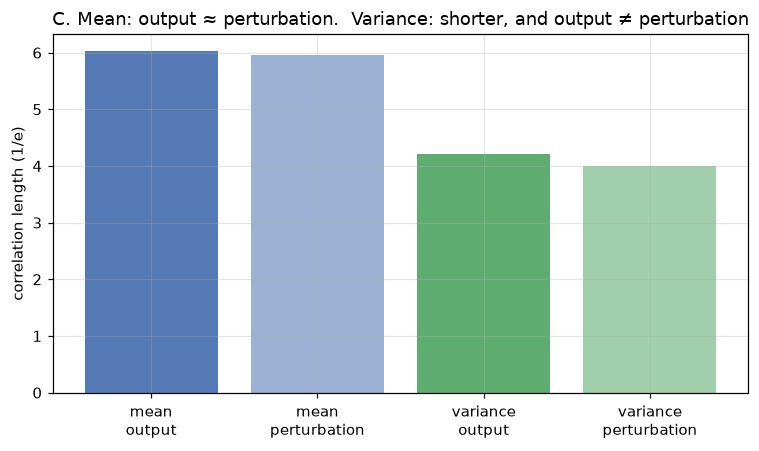

{'mean output': np.float64(6.03), 'mean perturbation': np.float64(5.97), 'variance output': np.float64(4.22), 'variance perturbation': np.float64(3.99)}


In [6]:
shape = (48, 48, 48); m = np.ones(shape, bool); N = 40
subs = np.stack([grf(shape, 4.0, seed=s) for s in range(N)])       # N correlated subjects, true L = 4
mean_out  = subs.mean(0);  mean_pert = (mean_out - subs[0])/(N-1)   # mean, and one LOO perturbation of it
var_out   = subs.var(0);   var_pert  = np.var(np.delete(subs, 0, 0), 0) - var_out
fields = {"mean\noutput": mean_out, "mean\nperturbation": mean_pert,
          "variance\noutput": var_out, "variance\nperturbation": var_pert}
Lvals = {k: corr_lengths(axis_profiles(masked_acf(v, m), 30)[0])[0] for k, v in fields.items()}

plt.figure(figsize=(7, 4.2))
cols = [to_rgba(b, a) for b, a in zip(["#4c72b0","#4c72b0","#55a868","#55a868"], [.95,.55,.95,.55])]
plt.bar(range(4), list(Lvals.values()), color=cols)
plt.xticks(range(4), list(fields)); plt.ylabel("correlation length (1/e)")
plt.title("C. Mean: output ≈ perturbation.  Variance: shorter, and output ≠ perturbation")
plt.tight_layout(); plt.show()
print({k.replace(chr(10),' '): round(v,2) for k, v in Lvals.items()})

**Read-off (C).** For the mean on these structure-free synthetic subjects, output and perturbation give the
same length (6.0 vs 6.0) — a consistency check. The decision this supports is unchanged: **size on the field the
noise protects (the LOO perturbations), not the output image.** What this section does *not* settle is *which
summary* of the perturbation field to size on: on real data the naive per-voxel maximum `S=maxᵢ|dᵢ|` turns out to
be **longer** than the mean image, not shorter (Part F) — the max is dominated by a few atrophy outliers whose
smooth regional loss re-injects long-range structure. So F sizes on an **outlier-resistant spread** of the
perturbations, and reports image vs max vs robust side by side rather than asserting a direction here.

## D — Is one size defensible across the whole brain?

Everything so far produced **one length for the whole volume**. But smoothness varies by position — cortex,
white matter and ventricles are not equally smooth — so a whole-brain length is really a *spatial average*,
and averaging an autocorrelation across different regions can mislead. This is a deliberately minimal two-region
check: does a single global size represent the regions, or neither?

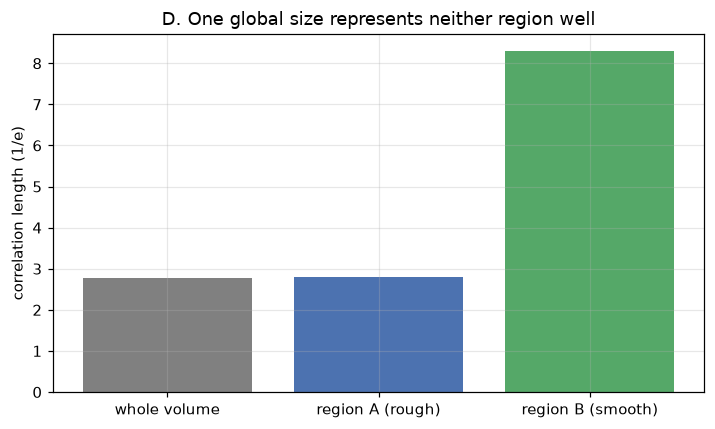

{'whole volume': np.float64(2.77), 'region A (rough)': np.float64(2.8), 'region B (smooth)': np.float64(8.29)}


In [7]:
shape = (48, 48, 48)
vol = np.empty(shape)
vol[:24] = grf(shape, 2.0, seed=10)[:24]           # region A: rough (short length)
vol[24:] = grf(shape, 6.0, seed=11)[24:]           # region B: smooth (long length)
regions = {"whole volume": np.ones(shape, bool)}
regions["region A (rough)"] = np.zeros(shape, bool); regions["region A (rough)"][:24] = True
regions["region B (smooth)"] = np.zeros(shape, bool); regions["region B (smooth)"][24:] = True
Lreg = {k: corr_lengths(axis_profiles(masked_acf(vol, mm), 30)[0])[0] for k, mm in regions.items()}

plt.figure(figsize=(6.6, 4))
plt.bar(range(3), list(Lreg.values()), color=["grey", "#4c72b0", "#55a868"])
plt.xticks(range(3), list(Lreg)); plt.ylabel("correlation length (1/e)")
plt.title("D. One global size represents neither region well")
plt.tight_layout(); plt.show()
print({k: round(v,2) for k, v in Lreg.items()})

**Read-off (D).** The two regions have clearly different lengths, and the global estimate matches neither (the
boundary and the rougher region dominate it). So **"one size everywhere" is a claim to defend, not a given.**
Kept minimal here; whether real brain smoothness varies enough to force region-specific sizing is an empirical
question for OASIS — the honest next diagnostic is a *local* smoothness map (a sliding window), which we add
only if this turns out to matter.

## E — Real OASIS

The same estimator on real gray-matter maps. Set `USE_OASIS = True` in an environment with `nilearn`; here it
falls back to a synthetic multi-axis field so the section runs anywhere. On OASIS this reports the per-axis
lengths (all three definitions) and the raw autocorrelation curves, with the estimator's own limits from A in
mind.

[fetch_oasis_vbm] Dataset directory found: /users/lukasschuler/nilearn_data/oasis1
[fetch_oasis_vbm] Dataset directory found: /users/lukasschuler/nilearn_data/oasis1
substrate: OASIS gray-matter maps   (mask covers 32% of the volume; voxel size (2.0, 2.0, 2.0) mm)
  axis 0:  1/e = 3.73   0.5 = 2.88   integral = 6.76
  axis 1:  1/e = 5.46   0.5 = 4.14   integral = 6.63
  axis 2:  1/e = 4.46   0.5 = 3.50   integral = 4.84


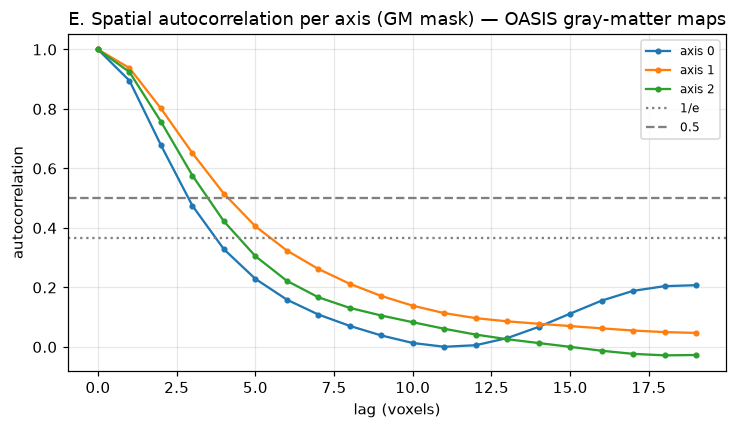

In [8]:
USE_OASIS = True                                   # set True where nilearn + network are available
note = None
if USE_OASIS:
    try:
        vols, _mask_raw = ph.load_oasis(n=40); note = "OASIS gray-matter maps"
    except Exception as e:
        USE_OASIS = False; note = f"synthetic (OASIS unavailable: {e})"
if not USE_OASIS:
    shape = (48, 48, 48)
    vols = np.stack([gaussian_filter(np.random.default_rng(s).standard_normal(shape),
                                     sigma=(3.0, 4.0, 5.5), mode="wrap") for s in range(40)])
    cc = np.stack(np.meshgrid(*[np.arange(48)-24]*3, indexing="ij")); mask = (cc**2).sum(0) < 22**2
    note = note or "synthetic stand-in (sphere mask, anisotropic)"
else:
    # measure within a real GM mask (same construction as 7.1), NOT the ~96% whole-head mask, which
    # would include near-constant background and inflate every correlation length.
    mask, _gm_thr = gm_threshold_mask(vols)
VOX = oasis_voxel_size_mm() if USE_OASIS else None

out_field = vols.mean(0)                              # the released mean map
print(f"substrate: {note}   (mask covers {mask.mean()*100:.0f}% of the volume"
      + (f"; voxel size {VOX} mm)" if VOX else ")"))
for ax, (le, lh, li) in enumerate(lengths_per_axis(out_field, mask)):
    print(f"  axis {ax}:  1/e = {le:.2f}   0.5 = {lh:.2f}   integral = {li:.2f}")
acf = masked_acf(out_field, mask)
plt.figure(figsize=(6.8, 4))
for ax, prof in enumerate(axis_profiles(acf, 20)):
    plt.plot(prof, "o-", ms=3, label=f"axis {ax}")
plt.axhline(1/np.e, color="grey", ls=":", label="1/e"); plt.axhline(0.5, color="grey", ls="--", label="0.5")
plt.xlabel("lag (voxels)"); plt.ylabel("autocorrelation"); plt.legend(fontsize=8)
plt.title(f"E. Spatial autocorrelation per axis (GM mask) — {note}"); plt.tight_layout(); plt.show()

## F — Size → dimensionality → hand-off to the noise construction

A measured length becomes a patch side through `side ≈ c · L`, where **`c`** is a design knob (how many
correlation lengths wide the patch is), fixed here at **`c = 1`** for the POC: the covariance mechanism only
exploits correlation within ~one length, and with 25–50% patch overlap the seams are already covered, so there
is no reason to use `c > 1` (its sensitivity is tabulated below).

We size on the **perturbation field** the noise must cover (finding C), but **not** on its per-voxel maximum
`S=maxᵢ|dᵢ|` and **not** on the L2-selected single subject: both are outlier-driven, and on OASIS (which
includes ~100 dementia subjects with smooth regional atrophy) the max re-injects long-range structure and comes
out *longer* than the mean image. Instead we size on an **outlier-resistant across-subject spread** of the LOO
perturbations (per-voxel std / trimmed spread), which reflects the typical scale the noise has to protect. This
is **decoupled from the mechanism's rejection bar**: the mechanism may key its bar on the L2-selected subject
(notebook 6.5); patch *sizing* uses the robust spread. The comparison below reports image vs max vs robust so
the inflation is visible, not asserted. Lengths are measured within the **GM mask** (as in 7.1) and, where the
voxel size is available, reported in **millimetres** so the rule ports across datasets.

Each geometry gives a voxel count `p`; the noise construction must span `min(p, N−1)` — the rank ceiling of the
LOO covariance (the full-rank requirement is notebook 6.1's result, carried across, not re-argued). At OASIS
scale `p ≫ N−1`, so geometry moves `p` (tiling and acceptance/fallback difficulty) while the dimensionality the
noise spans pins to `N−1`. **Open item (out of scope here):** patches are tiled with 25–50% overlap, and overlap
zones (voxels noised by several patches) introduce a separate privacy-compounding effect that must be handled in
the combination rule — see 7.1.

correlation length by sizing field (GM mask, 1/e):
            sizing field  1/e per axis cubic 1/e  cubic side (c=1)
              mean image 3.7, 5.5, 4.5       4.6                 5
       max_i|d_i|  (old) 3.7, 5.1, 4.5       4.4                 4
    std_i(d_i)  (robust) 4.0, 5.3, 4.8       4.7                 5
90%-trim RMS|d| (robust) 4.0, 5.1, 4.8       4.6                 5

headline sizing field = std_i(d_i)  (robust)  ·  c = 1
voxel ≈ 2.00 mm  ->  cubic length 4.7 vox = 9.4 mm  ->  side 5 vox = 10.0 mm  (port to another dataset by dividing mm by its voxel size)

c-sensitivity (cubic, robust field):
   c  cubic side   p
0.75           4  64
1.00           5 125
1.50           7 343

[feasibility] cubic p=125 vs rank ceiling N-1=39: p > rank -> noise spans min(p,N-1)=39 modes; a large p/rank gap is the rejection-wall regime (6.1-imaging) -- reported here, resolved elsewhere.


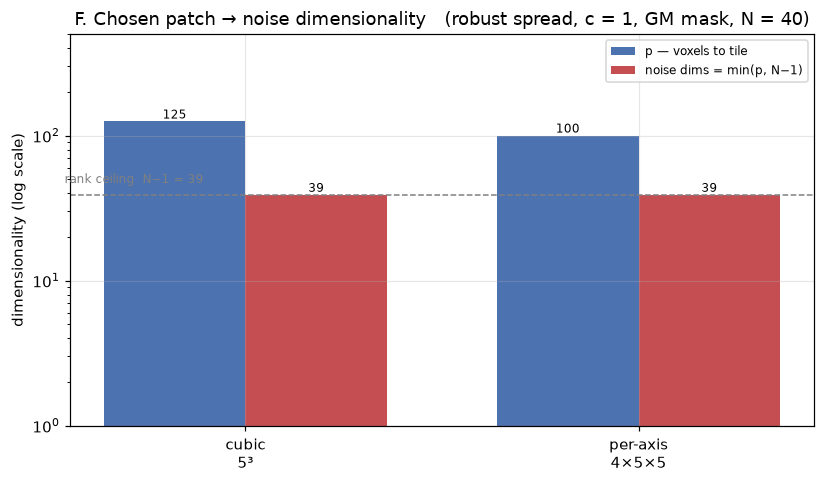

   patch side(s) robust 1/e length(s)   p  noise dims = min(p, N-1)
   cubic     5^3                  4.7 125                        39
per-axis   4x5x5        4.0, 5.3, 4.8 100                        39

[read-off F] within the mask: mean-image 1/e = 4.6, max_i|d_i| = 4.4, robust = 4.7. Here the max field is NOT longer than the image (4.4 vs 4.6); the outlier inflation does not show on this substrate (expected on structure-free synthetic data -- on OASIS the max inverts to longer). Sizing on the robust spread with c=1 gives a 5³ cubic patch (p=125, dims=39); much smaller than the old 35³ (max field + c=2 + 96% mask) -> smaller patches fall back more at k_check=N-1 (7.1 size-fallback result). per-axis ratio 1.2; the POC uses the cubic patch and notes the ratio as a caveat.


In [9]:
# --- F. Chosen patch, sized on a ROBUST across-subject spread within the GM mask, c = 1 (POC) ---
C_SIDE    = 1.0                       # patch side = c * (1/e length); c=1 for the POC (sensitivity below)
N         = int(vols.shape[0])
RANK_CEIL = N - 1                     # LOO covariance has at most N-1 nonzero modes (rank ceiling)

fields = sizing_fields(vols)          # mean image / max_i|d_i| / std_i(d_i) / 90%-trim RMS|d|
Lrows = {name: ([t[0] for t in lengths_per_axis(f, mask)],) for name, f in fields.items()}
Lrows = {name: (LE, float(np.mean(LE))) for name, (LE,) in Lrows.items()}

# side-by-side comparison so the max-field inflation vs the robust spread is visible
cmp = pd.DataFrame({"sizing field": list(Lrows),
                    "1/e per axis": [", ".join(f"{x:.1f}" for x in LE) for LE, _ in Lrows.values()],
                    "cubic 1/e": [f"{m:.1f}" for _, m in Lrows.values()],
                    "cubic side (c=1)": [max(2, int(round(C_SIDE*m))) for _, m in Lrows.values()]})
print("correlation length by sizing field (GM mask, 1/e):")
print(cmp.to_string(index=False)); print()

# headline sizing field: a robust spread (decided from the run; swap 'std' <-> trimmed as the numbers warrant)
SIZING = "std_i(d_i)  (robust)"
LE, L_cube = Lrows[SIZING]
side = lambda L: max(2, int(round(C_SIDE * L)))
side_cube, sides_ax = side(L_cube), [side(L) for L in LE]
p_cube, p_ax = side_cube**3, int(np.prod(sides_ax))
dims_cube, dims_ax = min(p_cube, RANK_CEIL), min(p_ax, RANK_CEIL)

# c-sensitivity and mm conversion
csens = pd.DataFrame({"c": [0.75, 1.0, 1.5],
                      "cubic side": [max(2, int(round(c*L_cube))) for c in [0.75, 1.0, 1.5]],
                      "p": [max(2, int(round(c*L_cube)))**3 for c in [0.75, 1.0, 1.5]]})
print(f"headline sizing field = {SIZING}  ·  c = {C_SIDE:g}")
if VOX:
    vmm = float(np.mean(VOX))
    print(f"voxel ≈ {vmm:.2f} mm  ->  cubic length {L_cube:.1f} vox = {L_cube*vmm:.1f} mm  ->  "
          f"side {side_cube} vox = {side_cube*vmm:.1f} mm  (port to another dataset by dividing mm by its voxel size)")
print("\nc-sensitivity (cubic, robust field):"); print(csens.to_string(index=False))

print(f"\n[feasibility] cubic p={p_cube} vs rank ceiling N-1={RANK_CEIL}: p "
      f"{'>>' if p_cube > 5*RANK_CEIL else '>'} rank -> noise spans min(p,N-1)={dims_cube} modes; a large "
      f"p/rank gap is the rejection-wall regime (6.1-imaging) -- reported here, resolved elsewhere.")

tbl = pd.DataFrame({"patch": ["cubic", "per-axis"],
                    "side(s)": [f"{side_cube}^3", "x".join(map(str, sides_ax))],
                    "robust 1/e length(s)": [f"{L_cube:.1f}", ", ".join(f"{L:.1f}" for L in LE)],
                    "p": [p_cube, p_ax],
                    "noise dims = min(p, N-1)": [dims_cube, dims_ax]})

fig, ax = plt.subplots(figsize=(7.6, 4.5))
xpos, w = np.arange(2), 0.36
groups = [f"cubic\n{side_cube}³", "per-axis\n" + "×".join(map(str, sides_ax))]
bp = ax.bar(xpos - w/2, [p_cube, p_ax],       w, color="#4c72b0", label="p — voxels to tile")
bd = ax.bar(xpos + w/2, [dims_cube, dims_ax], w, color="#c44e52", label="noise dims = min(p, N−1)")
ax.axhline(RANK_CEIL, color="grey", ls="--", lw=1)
ax.text(-0.46, RANK_CEIL*1.15, f"rank ceiling  N−1 = {RANK_CEIL}", color="grey", fontsize=8, va="bottom")
ax.set_yscale("log"); ax.set_ylim(1, max(p_cube, p_ax, RANK_CEIL) * 4)
ax.set_xticks(xpos); ax.set_xticklabels(groups); ax.set_ylabel("dimensionality (log scale)")
ax.set_title(f"F. Chosen patch → noise dimensionality   (robust spread, c = {C_SIDE:g}, GM mask, N = {N})")
for b in list(bp) + list(bd):
    ax.annotate(f"{int(b.get_height())}", (b.get_x()+b.get_width()/2, b.get_height()),
                ha="center", va="bottom", fontsize=8)
ax.legend(fontsize=8, loc="upper right"); plt.tight_layout(); plt.show()
print(tbl.to_string(index=False))

# data-driven read-off: states what the numbers show, flags the flipped claim and the 7.1 coupling
_img = Lrows["mean image"][1]; _max = Lrows["max_i|d_i|  (old)"][1]; _rob = L_cube
_inflated = _max > _img
_head = (f"The MAX field is LONGER than the image ({_max:.1f} vs {_img:.1f}) -> the old 'envelope cancels, so "
         f"the perturbation field is shorter' claim is CONTRADICTED; the per-voxel max is outlier-driven (atrophy)."
         if _inflated else
         f"Here the max field is NOT longer than the image ({_max:.1f} vs {_img:.1f}); the outlier inflation does "
         f"not show on this substrate (expected on structure-free synthetic data -- on OASIS the max inverts to longer).")
print(f"\n[read-off F] within the mask: mean-image 1/e = {_img:.1f}, max_i|d_i| = {_max:.1f}, robust = {_rob:.1f}. "
      + _head +
      f" Sizing on the robust spread with c={C_SIDE:g} gives a {side_cube}³ cubic patch (p={p_cube}, "
      f"dims={dims_cube}); {'much smaller than' if side_cube < 20 else 'compare to'} the old 35³ (max field "
      f"+ c=2 + 96% mask) -> smaller patches fall back more at k_check=N-1 (7.1 size-fallback result). per-axis "
      f"ratio {max(sides_ax)/max(1,min(sides_ax)):.1f}; the POC uses the cubic patch and notes the ratio as a caveat.")

## Conclusions & open decisions

- **The tool is validated** (A): FFT autocorrelation with mask correction recovers a known length to a few
  percent in the realistic short-length regime, and degrades gracefully when the length nears the region size.
- **Measure per axis always; size per axis when anisotropic** (B): per-axis lengths separate with the true
  structure; a cube mis-sizes when the ratio is well above 1. The POC uses a **cubic** patch and reports the
  per-axis ratio as a noted caveat (it sits in the ~1.4 grey zone).
- **Size on the perturbation field — but on a robust spread of it, not the max** (C/F): sizing on
  `S=maxᵢ|dᵢ|` (or the L2-selected subject) is outlier-driven and, on OASIS, comes out **longer** than the
  mean image — the *opposite* of the earlier draft's claim, which this re-run corrects. We size on an
  outlier-resistant across-subject spread, decoupled from the mechanism's L2-selected rejection bar (6.5).
- **One global size is a claim to defend** (D): regions differ and the global estimate represents neither;
  position-dependent sizing (a local smoothness map) is the extension, built only if OASIS forces it.
- **`c = 1` for the POC** (F): one correlation length, with overlap covering the seams; `c ∈ {0.75,1,1.5}`
  tabulated so the dependence is visible. Length defined consistently as **1/e**; sizing measured within the
  **GM mask** and reported in **millimetres** so the rule ports to datasets with other voxel sizes.
- **Sizing sets the noise dimensionality** (F): `side ≈ c·L → p`; the noise spans `min(p, N−1)`. At OASIS
  scale `p ≫ N−1`, so geometry moves `p` and the acceptance/fallback difficulty while the rank pins to `N−1`.

**Coupling to 7.1 (surfaced, not silent):** the corrected size is substantially **smaller** than the earlier
35³, because that number combined three separate inflations — the `max` field, `c = 2`, and the ~96% mask —
all removed here. A smaller patch means **higher per-patch fallback** at `k_check = N−1` (7.1's size↔fallback
result), so the patch size chosen here and the operating point (scale / k_check) chosen in the privacy eval are
one coupled decision.

**Open items:** **overlap** (25–50%) introduces a privacy-compounding effect in overlap zones, handled in the
combination rule (7.1), not here; **position-dependent sizing** is the extension of D. *No DP guarantees; this
notebook sizes patches, it does not make privacy claims.*

## Changelog (this revision)

- **Flipped C/F's central claim.** The earlier draft said the perturbation/sensitivity field is *shorter* than
  the mean image (the anatomical envelope "cancels"). The executed OASIS run shows the opposite: `S=maxᵢ|dᵢ|` is
  **longer** (17.4 vs ~14), because the per-voxel max is dominated by atrophy outliers. Corrected in C, F, and
  Conclusions.
- **Sizing field changed** from the outlier-driven `maxᵢ|dᵢ|` to an **outlier-resistant spread** (std / trimmed),
  with image vs max vs robust reported side by side; explicitly decoupled from the mechanism's L2-selected bar.
- **Mask changed** from the ~96% whole-head mask to the **GM-threshold mask** used in 7.1, so lengths aren't
  measured over background.
- **`c` set to 1** (was 2) for the POC, with a `c ∈ {0.75,1,1.5}` sensitivity table; **1/e** used consistently;
  **mm-based** sizing added (voxel size read from the image header).
- **Net effect:** the recommended patch is **much smaller** than the old 35³ (three inflations removed), which
  **raises per-patch fallback** in 7.1 — surfaced as a coupling to the operating-point decision, not hidden.
- Read-offs now derive from each cell's printed numbers; feasibility flag (`p` vs `N−1`) and the overlap
  privacy-compounding open item stated explicitly.